# Bristol Rental Intelligence

## Notebook 1: Data acquisition and initial inspection

**Objective:** Obtain official private-rent data from the Office for National Statistics (ONS), identify the Bristol records, and inspect the available variables.

**Data source:** ONS Price Index of Private Rents (PIPR), monthly price statistics.

**Important limitation:** These are official area-level estimates, not individual rental listings. Therefore, this project will analyse rent trends and create forecasts or comparisons; it will not claim to estimate the price of one specific flat.

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find the main project folder.
# If the notebook starts inside /notebooks, move one level up.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw-data folder: {RAW_DATA_DIR}")
print(f"Pandas version: {pd.__version__}")

In [34]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw-data folder: {RAW_DATA_DIR}")

Project root: /Users/Chibaba/Documents/Projects/bristol-rental-intelligence/notebooks
Raw-data folder: /Users/Chibaba/Documents/Projects/bristol-rental-intelligence/notebooks/data/raw


In [35]:
import pandas as pd

print("Python and pandas are working!")
print(pd.__version__)

Python and pandas are working!
3.0.6


In [39]:
import openpyxl

print("Excel support is ready.")

Excel support is ready.


In [36]:
from pathlib import Path
import pandas as pd

# Identify the main project folder.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Build the full path to the downloaded source file.
DATA_FILE = PROJECT_ROOT / "data" / "raw" / "ons_pipr_monthly_prices.xlsx"

# Stop with a helpful message if Python cannot find the file.
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"File not found: {DATA_FILE}\n"
        "Check that the file is inside data/raw and has the exact required name."
    )

# Open the Excel workbook and list every worksheet inside it.
excel_workbook = pd.ExcelFile(DATA_FILE)

print("Workbook found successfully.")
print("\nWorksheets available:")
for sheet in excel_workbook.sheet_names:
    print(f"- {sheet}")

Workbook found successfully.

Worksheets available:
- Cover sheet
- Contents
- Notes
- Table 1


In [37]:
# Load Table 1 without assuming that the first row contains column names.
raw_table = pd.read_excel(
    DATA_FILE,
    sheet_name="Table 1",
    header=None
)

print(f"Rows: {raw_table.shape[0]:,}")
print(f"Columns: {raw_table.shape[1]:,}")

# Display the first 25 rows and first 12 columns.
raw_table.iloc[:25, :12]

Rows: 49,983
Columns: 40


,0,1,2,3,4,5,6,7,8,9,10,11
0,"Price Index of Private Rents, UK: monthly pric...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,This worksheet contains one table. Some cells ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Time period,Area code,Area name,Region or country name,Index,Monthly change,Annual change,Rental price,Index one bed,Monthly change one bed,Annual change one bed,Rental price one bed
3,2015-01-01 00:00:00,K02000001,United Kingdom,[z],81.258259,[x],[x],910,82.339979,[x],[x],736
4,2015-02-01 00:00:00,K02000001,United Kingdom,[z],81.413747,0.191351,[x],912,82.53953,0.24235,[x],738
5,2015-03-01 00:00:00,K02000001,United Kingdom,[z],81.663685,0.306997,[x],915,82.781781,0.293496,[x],740
6,2015-04-01 00:00:00,K02000001,United Kingdom,[z],81.990506,0.400204,[x],918,83.232795,0.544823,[x],744
7,2015-05-01 00:00:00,K02000001,United Kingdom,[z],82.343646,0.430708,[x],922,83.597644,0.438349,[x],748
8,2015-06-01 00:00:00,K02000001,United Kingdom,[z],82.498421,0.187963,[x],924,83.79195,0.232429,[x],749
9,2015-07-01 00:00:00,K02000001,United Kingdom,[z],82.668782,0.206502,[x],926,84.058943,0.318639,[x],752


In [23]:
# Reload Table 1 using row 2 as the column-header row.
rent_data = pd.read_excel(
    DATA_FILE,
    sheet_name="Table 1",
    header=2
)

print(f"Dataset shape: {rent_data.shape[0]:,} rows and {rent_data.shape[1]} columns")

print("\nColumn names:")
for number, column in enumerate(rent_data.columns, start=1):
    print(f"{number}. {column}")

# Display the first five records with the real column names.
rent_data.head()

Dataset shape: 49,980 rows and 40 columns

Column names:
1. Time period
2. Area code
3. Area name
4. Region or country name
5. Index
6. Monthly change
7. Annual change
8. Rental price
9. Index one bed
10. Monthly change one bed
11. Annual change one bed
12. Rental price one bed
13. Index two bed
14. Monthly change two bed
15. Annual change two bed
16. Rental price two bed
17. Index three bed
18. Monthly change three bed
19. Annual change three bed
20. Rental price three bed
21. Index four or more bed
22. Monthly change four or more bed
23. Annual change four or more bed
24. Rental price four or more bed
25. Index detached
26. Monthly change detached
27. Annual change detached
28. Rental price detached
29. Index semidetached
30. Monthly change semidetached
31. Annual change semidetached
32. Rental price semidetached
33. Index terraced
34. Monthly change terraced
35. Annual change terraced
36. Rental price terraced
37. Index flat maisonette
38. Monthly change flat maisonette
39. Annual c

,Time period,Area code,Area name,Region or country name,Index,Monthly change,Annual change,Rental price,Index one bed,Monthly change one bed,...,Annual change semidetached,Rental price semidetached,Index terraced,Monthly change terraced,Annual change terraced,Rental price terraced,Index flat maisonette,Monthly change flat maisonette,Annual change flat maisonette,Rental price flat maisonette
0,2015-01-01,K02000001,United Kingdom,[z],81.258259,[x],[x],910,82.339979,[x],...,[x],897,80.345118,[x],[x],893,83.26757,[x],[x],904
1,2015-02-01,K02000001,United Kingdom,[z],81.413747,0.191351,[x],912,82.53953,0.24235,...,[x],899,80.478716,0.166281,[x],894,83.457123,0.227644,[x],906
2,2015-03-01,K02000001,United Kingdom,[z],81.663685,0.306997,[x],915,82.781781,0.293496,...,[x],901,80.72993,0.312149,[x],897,83.73479,0.332706,[x],909
3,2015-04-01,K02000001,United Kingdom,[z],81.990506,0.400204,[x],918,83.232795,0.544823,...,[x],904,80.995081,0.328442,[x],900,84.194112,0.548543,[x],914
4,2015-05-01,K02000001,United Kingdom,[z],82.343646,0.430708,[x],922,83.597644,0.438349,...,[x],908,81.33684,0.421951,[x],904,84.638073,0.527307,[x],918


In [24]:
# Find every area whose name contains the word "Bristol".
bristol_candidates = rent_data[
    rent_data["Area name"]
    .astype(str)
    .str.contains("Bristol", case=False, na=False)
]

# Summarise each matching area.
bristol_area_summary = (
    bristol_candidates
    .groupby(
        ["Area code", "Area name", "Region or country name"],
        as_index=False
    )
    .agg(
        first_month=("Time period", "min"),
        latest_month=("Time period", "max"),
        number_of_records=("Time period", "count")
    )
)

bristol_area_summary

,Area code,Area name,Region or country name,first_month,latest_month,number_of_records
0,E06000023,"Bristol, City of",South West,2015-01-01,2026-08-01,140


In [25]:
# Official ONS area code for Bristol, City of.
BRISTOL_AREA_CODE = "E06000023"

# Keep only records for Bristol and make an independent copy.
bristol_data = (
    rent_data
    .loc[rent_data["Area code"] == BRISTOL_AREA_CODE]
    .copy()
)

# Arrange records from oldest to newest month.
bristol_data = bristol_data.sort_values("Time period").reset_index(drop=True)

# Confirm that filtering worked.
print(f"Number of Bristol records: {len(bristol_data)}")
print(f"Area name: {bristol_data['Area name'].iloc[0]}")
print(f"Date range: {bristol_data['Time period'].min():%B %Y} "
      f"to {bristol_data['Time period'].max():%B %Y}")

# Show the main rental-price columns for the first five Bristol months.
bristol_data[
    [
        "Time period",
        "Area code",
        "Area name",
        "Rental price",
        "Rental price one bed",
        "Rental price two bed",
        "Rental price three bed",
        "Rental price four or more bed"
    ]
].head()

Number of Bristol records: 140
Area name: Bristol, City of
Date range: January 2015 to August 2026


,Time period,Area code,Area name,Rental price,Rental price one bed,Rental price two bed,Rental price three bed,Rental price four or more bed
0,2015-01-01,E06000023,"Bristol, City of",1041,670,864,959,1441
1,2015-02-01,E06000023,"Bristol, City of",1045,673,868,963,1447
2,2015-03-01,E06000023,"Bristol, City of",1050,676,872,968,1454
3,2015-04-01,E06000023,"Bristol, City of",1053,679,875,971,1457
4,2015-05-01,E06000023,"Bristol, City of",1058,681,878,975,1463


In [26]:
# Select the fields that will be useful for analysis and visualisation.
analysis_columns = [
    "Time period",
    "Rental price",
    "Annual change",
    "Rental price one bed",
    "Rental price two bed",
    "Rental price three bed",
    "Rental price four or more bed",
    "Rental price detached",
    "Rental price semidetached",
    "Rental price terraced",
    "Rental price flat maisonette"
]

bristol_analysis = bristol_data[analysis_columns].copy()

# Create a compact data-quality report.
quality_report = pd.DataFrame({
    "data_type": bristol_analysis.dtypes.astype(str),
    "missing_values": bristol_analysis.isna().sum(),
    "missing_percent": (
        bristol_analysis.isna().mean() * 100
    ).round(2),
    "unique_values": bristol_analysis.nunique()
})

print(
    "Duplicate monthly records:",
    bristol_analysis["Time period"].duplicated().sum()
)

quality_report

Duplicate monthly records: 0


,data_type,missing_values,missing_percent,unique_values
Time period,datetime64[us],0,0.0,140
Rental price,object,0,0.0,129
Annual change,object,0,0.0,129
Rental price one bed,object,0,0.0,124
Rental price two bed,object,0,0.0,126
Rental price three bed,object,0,0.0,123
Rental price four or more bed,object,0,0.0,133
Rental price detached,object,0,0.0,130
Rental price semidetached,object,0,0.0,129
Rental price terraced,object,0,0.0,128


In [27]:
# All columns except the date column should eventually become numeric.
numeric_columns = [
    column
    for column in bristol_analysis.columns
    if column != "Time period"
]

conversion_check = []

for column in numeric_columns:
    original_values = bristol_analysis[column]

    # Try to convert each value to a number.
    converted_values = pd.to_numeric(
        original_values,
        errors="coerce"
    )

    # Identify values that were present but could not become numbers.
    invalid_values = original_values[
        converted_values.isna() & original_values.notna()
    ]

    conversion_check.append({
        "column": column,
        "values_that_cannot_convert": len(invalid_values),
        "examples_of_non_numeric_values": (
            ", ".join(
                invalid_values.astype(str).unique()[:5]
            )
            if len(invalid_values) > 0
            else "None"
        )
    })

conversion_report = pd.DataFrame(conversion_check)
conversion_report

,column,values_that_cannot_convert,examples_of_non_numeric_values
0,Rental price,0,None
1,Annual change,12,[x]
2,Rental price one bed,0,None
3,Rental price two bed,0,None
4,Rental price three bed,0,None
5,Rental price four or more bed,0,None
6,Rental price detached,0,None
7,Rental price semidetached,0,None
8,Rental price terraced,0,None
9,Rental price flat maisonette,0,None


In [28]:
# Make a new cleaned version.
# Keep bristol_analysis unchanged as our extracted source table.
bristol_clean = bristol_analysis.copy()

# Convert every rent-related column to numeric values.
for column in numeric_columns:
    bristol_clean[column] = pd.to_numeric(
        bristol_clean[column],
        errors="coerce"
    )

# Confirm the cleaned data structure.
print("Data types after cleaning:")
print(bristol_clean.dtypes)

print("\nMissing annual-change values:")
print(bristol_clean["Annual change"].isna().sum())

print("\nDuplicate monthly records:")
print(bristol_clean["Time period"].duplicated().sum())

# Review the first 15 months.
bristol_clean.head(15)

Data types after cleaning:
Time period                      datetime64[us]
Rental price                              int64
Annual change                           float64
Rental price one bed                      int64
Rental price two bed                      int64
Rental price three bed                    int64
Rental price four or more bed             int64
Rental price detached                     int64
Rental price semidetached                 int64
Rental price terraced                     int64
Rental price flat maisonette              int64
dtype: object

Missing annual-change values:
12

Duplicate monthly records:
0


,Time period,Rental price,Annual change,Rental price one bed,Rental price two bed,Rental price three bed,Rental price four or more bed,Rental price detached,Rental price semidetached,Rental price terraced,Rental price flat maisonette
0,2015-01-01,1041,NaN,670,864,959,1441,1175,1146,1106,838
1,2015-02-01,1045,NaN,673,868,963,1447,1180,1151,1111,842
2,2015-03-01,1050,NaN,676,872,968,1454,1185,1156,1116,846
3,2015-04-01,1053,NaN,679,875,971,1457,1189,1160,1120,848
4,2015-05-01,1058,NaN,681,878,975,1463,1194,1164,1124,852
5,2015-06-01,1061,NaN,684,882,979,1464,1198,1168,1127,855
6,2015-07-01,1064,NaN,686,885,983,1467,1203,1172,1130,858
7,2015-08-01,1069,NaN,689,889,988,1473,1210,1178,1134,862
8,2015-09-01,1074,NaN,692,894,992,1482,1216,1184,1140,866
9,2015-10-01,1079,NaN,695,897,997,1489,1221,1189,1145,870


In [29]:
# Define where the cleaned dataset will be saved.
CLEAN_DATA_FILE = (
    PROCESSED_DATA_DIR / "bristol_rental_prices_clean.csv"
)

# Save as CSV without the automatic pandas row-number column.
bristol_clean.to_csv(
    CLEAN_DATA_FILE,
    index=False
)

# Confirm that the file was created.
print("Clean dataset saved successfully.")
print(f"Location: {CLEAN_DATA_FILE}")
print(f"File size: {CLEAN_DATA_FILE.stat().st_size / 1024:.1f} KB")

Clean dataset saved successfully.
Location: /Users/Chibaba/Documents/Projects/bristol-rental-intelligence/notebooks/data/processed/bristol_rental_prices_clean.csv
File size: 8.9 KB


In [30]:
from pathlib import Path
from shutil import move

# The notebook is stored inside the notebooks folder.
NOTEBOOK_DIR = Path.cwd().resolve()

# The parent folder is the actual project root.
PROJECT_ROOT = NOTEBOOK_DIR.parent

# Correct project-level data locations.
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Current incorrect locations created inside notebooks/data/.
old_raw_file = (
    NOTEBOOK_DIR / "data" / "raw" / "ons_pipr_monthly_prices.xlsx"
)

old_clean_file = (
    NOTEBOOK_DIR / "data" / "processed" / "bristol_rental_prices_clean.csv"
)

# Correct destinations at the project level.
DATA_FILE = RAW_DATA_DIR / "ons_pipr_monthly_prices.xlsx"
CLEAN_DATA_FILE = (
    PROCESSED_DATA_DIR / "bristol_rental_prices_clean.csv"
)

# Move each file only if it exists in the old location
# and is not already in the correct location.
if old_raw_file.exists() and not DATA_FILE.exists():
    move(str(old_raw_file), str(DATA_FILE))

if old_clean_file.exists() and not CLEAN_DATA_FILE.exists():
    move(str(old_clean_file), str(CLEAN_DATA_FILE))

print("Project root:", PROJECT_ROOT)
print("Raw dataset exists:", DATA_FILE.exists())
print("Clean dataset exists:", CLEAN_DATA_FILE.exists())
print("Clean-dataset location:", CLEAN_DATA_FILE)

Project root: /Users/Chibaba/Documents/Projects/bristol-rental-intelligence
Raw dataset exists: True
Clean dataset exists: True
Clean-dataset location: /Users/Chibaba/Documents/Projects/bristol-rental-intelligence/data/processed/bristol_rental_prices_clean.csv


In [31]:
# Select the first and latest monthly observations.
first_observation = bristol_clean.iloc[0]
latest_observation = bristol_clean.iloc[-1]

# Calculate change across the full available time period.
starting_rent = first_observation["Rental price"]
latest_rent = latest_observation["Rental price"]

absolute_change = latest_rent - starting_rent
percentage_change = (
    (latest_rent - starting_rent) / starting_rent * 100
)

# Create a readable project summary.
rent_growth_summary = pd.DataFrame({
    "Metric": [
        "First month",
        "Latest month",
        "Average monthly rent in first month",
        "Average monthly rent in latest month",
        "Total change in monthly rent",
        "Percentage change over full period",
        "Latest annual rent change"
    ],
    "Value": [
        first_observation["Time period"].strftime("%B %Y"),
        latest_observation["Time period"].strftime("%B %Y"),
        f"£{starting_rent:,.0f}",
        f"£{latest_rent:,.0f}",
        f"£{absolute_change:,.0f}",
        f"{percentage_change:.1f}%",
        f"{latest_observation['Annual change']:.1f}%"
    ]
})

rent_growth_summary

,Metric,Value
0,First month,January 2015
1,Latest month,August 2026
2,Average monthly rent in first month,"£1,041"
3,Average monthly rent in latest month,"£1,883"
4,Total change in monthly rent,£842
5,Percentage change over full period,80.9%
6,Latest annual rent change,5.9%


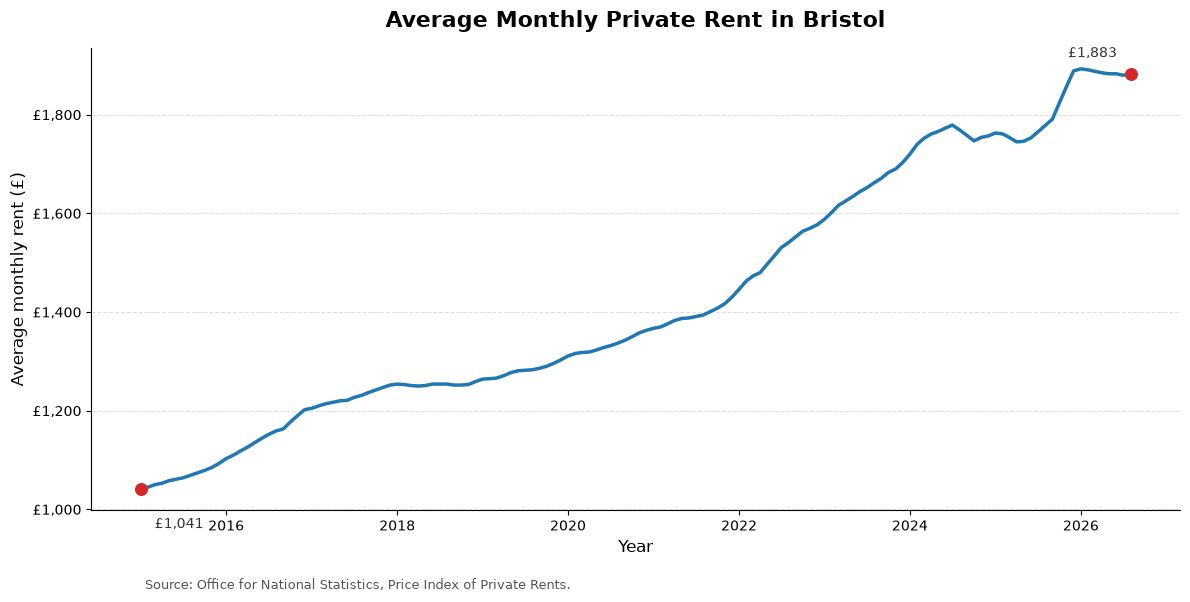

Chart saved to: /Users/Chibaba/Documents/Projects/bristol-rental-intelligence/reports/figures/bristol_overall_rent_trend.png


In [32]:
from matplotlib.ticker import FuncFormatter

# Create a folder for charts used in the project report and README.
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Set up the chart.
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    bristol_clean["Time period"],
    bristol_clean["Rental price"],
    color="#1f77b4",
    linewidth=2.5,
    label="Average monthly private rent"
)

# Highlight the first and latest data points.
ax.scatter(
    [first_observation["Time period"], latest_observation["Time period"]],
    [starting_rent, latest_rent],
    color="#d62728",
    s=70,
    zorder=3
)

# Add labels to the two highlighted points.
ax.annotate(
    f"£{starting_rent:,.0f}",
    xy=(first_observation["Time period"], starting_rent),
    xytext=(10, -28),
    textcoords="offset points",
    color="#333333"
)

ax.annotate(
    f"£{latest_rent:,.0f}",
    xy=(latest_observation["Time period"], latest_rent),
    xytext=(-45, 12),
    textcoords="offset points",
    color="#333333"
)

# Format the chart for readability.
ax.set_title(
    "Average Monthly Private Rent in Bristol",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Average monthly rent (£)", fontsize=12)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"£{value:,.0f}")
)

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add a source note beneath the chart.
fig.text(
    0.125,
    0.01,
    "Source: Office for National Statistics, Price Index of Private Rents.",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Save a high-quality PNG for the README and final report.
figure_path = FIGURE_DIR / "bristol_overall_rent_trend.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved to: {figure_path}")

In [40]:
# Map clear bedroom labels to the relevant dataset columns.
bedroom_columns = {
    "One bedroom": "Rental price one bed",
    "Two bedrooms": "Rental price two bed",
    "Three bedrooms": "Rental price three bed",
    "Four or more bedrooms": "Rental price four or more bed"
}

# Build a comparison table using the first and latest monthly records.
bedroom_summary = pd.DataFrame([
    {
        "Property size": label,
        "January 2015 rent (£)": first_observation[column],
        "August 2026 rent (£)": latest_observation[column],
        "Increase (£)": latest_observation[column] - first_observation[column],
        "Increase (%)": round(
            (
                (latest_observation[column] - first_observation[column])
                / first_observation[column]
                * 100
            ),
            1
        )
    }
    for label, column in bedroom_columns.items()
])

bedroom_summary

,Property size,January 2015 rent (£),August 2026 rent (£),Increase (£),Increase (%)
0,One bedroom,670,1225,555,82.8
1,Two bedrooms,864,1544,680,78.7
2,Three bedrooms,959,1759,800,83.4
3,Four or more bedrooms,1441,2546,1105,76.7


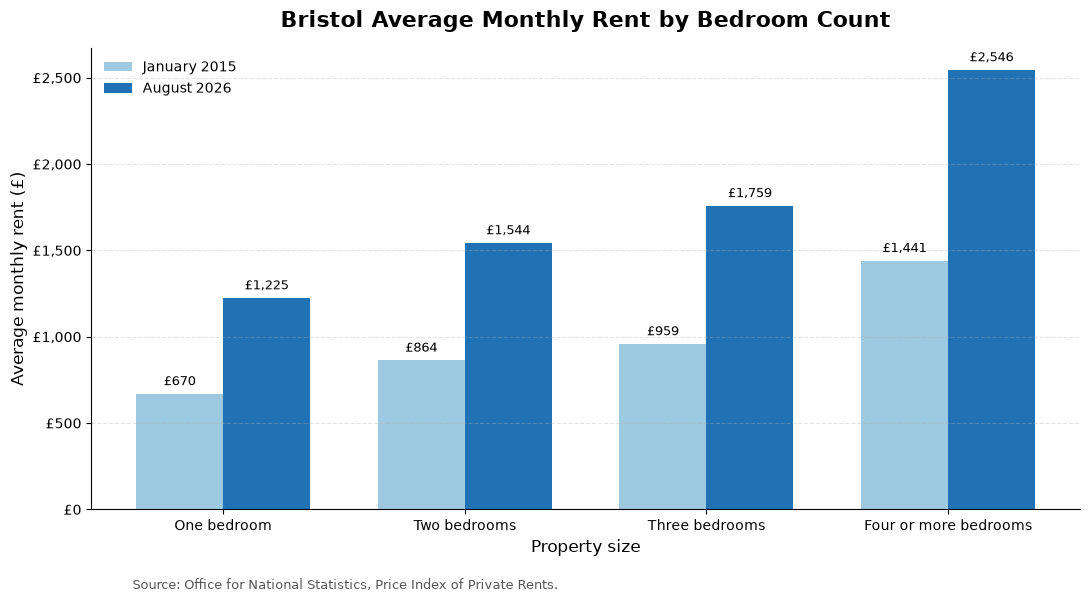

Chart saved to: /Users/Chibaba/Documents/Projects/bristol-rental-intelligence/reports/figures/bristol_rent_by_bedroom_count.png


In [41]:
import numpy as np

# Values used for the two periods.
property_sizes = bedroom_summary["Property size"]
rents_2015 = bedroom_summary["January 2015 rent (£)"]
rents_2026 = bedroom_summary["August 2026 rent (£)"]

# Bar positions and width.
positions = np.arange(len(property_sizes))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

# Draw paired bars for 2015 and 2026.
bars_2015 = ax.bar(
    positions - bar_width / 2,
    rents_2015,
    bar_width,
    label="January 2015",
    color="#9ecae1"
)

bars_2026 = ax.bar(
    positions + bar_width / 2,
    rents_2026,
    bar_width,
    label="August 2026",
    color="#2171b5"
)

# Add pound-value labels above each bar.
for bars in [bars_2015, bars_2026]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"£{height:,.0f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )

# Format the chart.
ax.set_title(
    "Bristol Average Monthly Rent by Bedroom Count",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Property size", fontsize=12)
ax.set_ylabel("Average monthly rent (£)", fontsize=12)

ax.set_xticks(positions)
ax.set_xticklabels(property_sizes)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"£{value:,.0f}")
)

ax.legend(frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.125,
    0.01,
    "Source: Office for National Statistics, Price Index of Private Rents.",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Save for use in the README and final project report.
bedroom_figure_path = (
    FIGURE_DIR / "bristol_rent_by_bedroom_count.png"
)

fig.savefig(
    bedroom_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved to: {bedroom_figure_path}")

Highest annual rent growth: 11.1% in October 2022


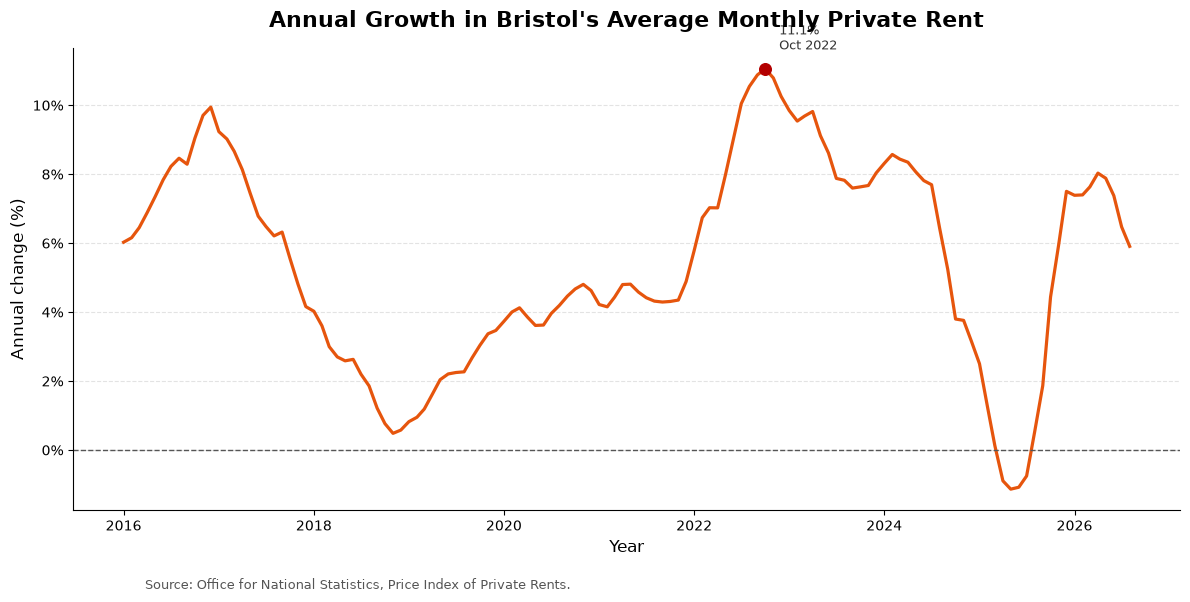

Chart saved to: /Users/Chibaba/Documents/Projects/bristol-rental-intelligence/reports/figures/bristol_annual_rent_growth.png


In [42]:
# Exclude the first 12 months because annual change is unavailable there.
annual_change_data = bristol_clean.dropna(
    subset=["Annual change"]
).copy()

# Find the month with the largest year-on-year rent increase.
peak_growth_row = annual_change_data.loc[
    annual_change_data["Annual change"].idxmax()
]

print(
    "Highest annual rent growth:",
    f"{peak_growth_row['Annual change']:.1f}%",
    "in",
    peak_growth_row["Time period"].strftime("%B %Y")
)

# Create the chart.
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    annual_change_data["Time period"],
    annual_change_data["Annual change"],
    color="#e6550d",
    linewidth=2.3
)

# Add a zero-growth reference line.
ax.axhline(
    y=0,
    color="#555555",
    linewidth=1,
    linestyle="--"
)

# Highlight the highest observed annual growth rate.
ax.scatter(
    peak_growth_row["Time period"],
    peak_growth_row["Annual change"],
    color="#b30000",
    s=70,
    zorder=3
)

ax.annotate(
    (
        f"{peak_growth_row['Annual change']:.1f}%\n"
        f"{peak_growth_row['Time period'].strftime('%b %Y')}"
    ),
    xy=(
        peak_growth_row["Time period"],
        peak_growth_row["Annual change"]
    ),
    xytext=(10, 14),
    textcoords="offset points",
    fontsize=9,
    color="#333333"
)

# Format the chart.
ax.set_title(
    "Annual Growth in Bristol's Average Monthly Private Rent",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Annual change (%)", fontsize=12)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value:.0f}%")
)

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.125,
    0.01,
    "Source: Office for National Statistics, Price Index of Private Rents.",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Save the chart.
annual_change_figure_path = (
    FIGURE_DIR / "bristol_annual_rent_growth.png"
)

fig.savefig(
    annual_change_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved to: {annual_change_figure_path}")